K-MEANS CLUSTER ANALYSIS

Dataset found:
healthcare_dataset.csv

Dataset loaded successfully.
Total records: 55500

CLUSTERING SAMPLE
Number of observations used: 55392

Descriptive Statistics:
       Age_Clean  Billing_Clean  Length_of_Stay
count   55392.00       55392.00        55392.00
mean       51.54       25590.08           15.51
std        19.60       14178.66            8.66
min        13.00           9.24            1.00
25%        35.00       13297.48            8.00
50%        52.00       25573.82           15.00
75%        68.00       37849.21           23.00
max        89.00       52764.28           30.00

STANDARDIZATION CHECK
---------------------------------------------------------------------------
Average standardized mean: 0.0
Average standardized standard deviation: 1.0

ELBOW METHOD RESULTS
K = 1  Inertia = 166176.0
K = 2  Inertia = 124496.94
K = 3  Inertia = 99287.37
K = 4  Inertia = 79233.33
K = 5  Inertia = 66316.15
K = 6  Inertia = 55086.0
K = 7  Inertia = 4812

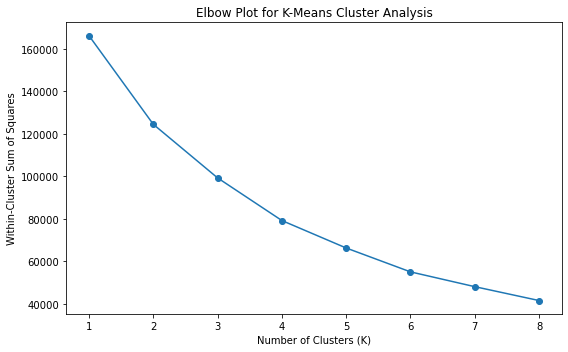


SILHOUETTE SCORES
K = 2  Silhouette Score = 0.2441
K = 3  Silhouette Score = 0.2404
K = 4  Silhouette Score = 0.262
K = 5  Silhouette Score = 0.2689

FINAL K-MEANS MODEL: K = 4

CLUSTER SIZES
---------------------------------------------------------------------------
0    13980
1    13668
2    13933
3    13811
Name: Cluster, dtype: int64

CLUSTER PERCENTAGES
---------------------------------------------------------------------------
0    25.24
1    24.68
2    25.15
3    24.93
Name: Cluster, dtype: float64

CLUSTER MEANS
         Age_Clean  Billing_Clean  Length_of_Stay
Cluster                                          
0            67.00       22716.52           23.75
1            35.27       12423.67           13.83
2            35.96       39099.58           16.80
3            67.71       27900.07            7.52

CLUSTER MEDIANS
---------------------------------------------------------------------------
         Age_Clean  Billing_Clean  Length_of_Stay
Cluster                       

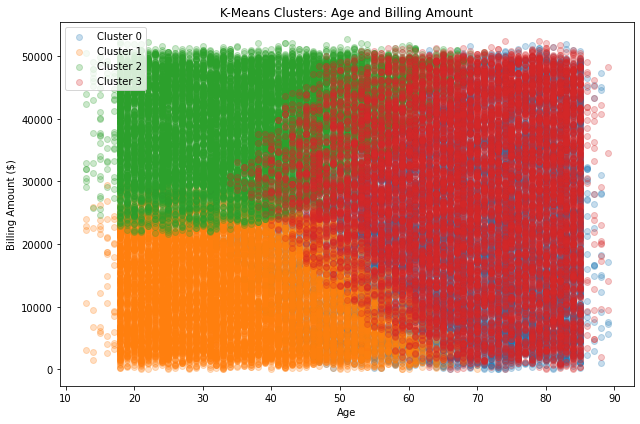

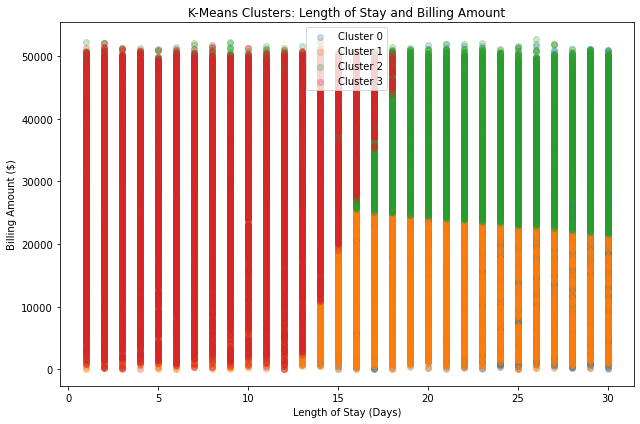

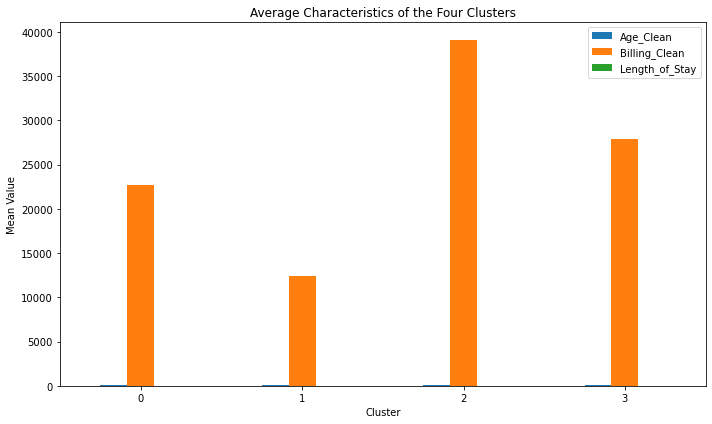


FINAL CLUSTER SUMMARY

Cluster 0
N = 13980
Percent = 25.24 %
Mean Age = 67.0
Mean Billing Amount = $ 22716.52
Mean Length of Stay = 23.75 days

Cluster 1
N = 13668
Percent = 24.68 %
Mean Age = 35.27
Mean Billing Amount = $ 12423.67
Mean Length of Stay = 13.83 days

Cluster 2
N = 13933
Percent = 25.15 %
Mean Age = 35.96
Mean Billing Amount = $ 39099.58
Mean Length of Stay = 16.8 days

Cluster 3
N = 13811
Percent = 24.93 %
Mean Age = 67.71
Mean Billing Amount = $ 27900.07
Mean Length of Stay = 7.52 days

ANALYSIS COMPLETED SUCCESSFULLY


In [1]:
# Project Title

#**K-Means Cluster Analysis of Patient Age, Billing Amount, and Length of Stay**

## Purpose

#For this assignment, I used k-means cluster analysis to identify subgroups of hospitalization records with similar patterns across three quantitative variables:

#- Age
#- Billing Amount
#- Length of Stay

#Because these variables are measured on very different scales, I standardized them before performing the cluster analysis. Standardization gives each variable approximately equal influence on the clustering process.

#The analysis included **55,392 valid observations** after excluding records with invalid or missing values.

#I did not divide the data into separate training and test samples because the assignment requires the cluster analysis to be performed only once, and the purpose here is exploratory identification of subgroups rather than supervised prediction.

## Complete Python Program

#```python id="yf20io"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ============================================================
# K-MEANS CLUSTER ANALYSIS
# ============================================================

print("=" * 75)
print("K-MEANS CLUSTER ANALYSIS")
print("=" * 75)

# ============================================================
# STEP 1: FIND DATASET
# ============================================================

csv_files = glob.glob("**/*.csv", recursive=True)

data_file = None

for file in csv_files:
    if os.path.basename(file).lower() == "healthcare_dataset.csv":
        data_file = file
        break

if data_file is None:
    for file in csv_files:
        if "healthcare" in os.path.basename(file).lower():
            data_file = file
            break

if data_file is None and len(csv_files) == 1:
    data_file = csv_files[0]

if data_file is None:
    raise FileNotFoundError(
        "healthcare_dataset.csv was not found. "
        "Please upload the healthcare CSV file first."
    )

print("\nDataset found:")
print(data_file)

# ============================================================
# STEP 2: LOAD DATA
# ============================================================

data = pd.read_csv(
    data_file,
    low_memory=False
)

data.columns = data.columns.str.strip()

print("\nDataset loaded successfully.")
print("Total records:", len(data))

# ============================================================
# STEP 3: CLEAN AGE
# ============================================================

data["Age_Clean"] = pd.to_numeric(
    data["Age"],
    errors="coerce"
)

data.loc[
    (data["Age_Clean"] < 0) |
    (data["Age_Clean"] > 120),
    "Age_Clean"
] = np.nan

# ============================================================
# STEP 4: CLEAN BILLING AMOUNT
# ============================================================

data["Billing_Clean"] = pd.to_numeric(
    data["Billing Amount"],
    errors="coerce"
)

data.loc[
    data["Billing_Clean"] <= 0,
    "Billing_Clean"
] = np.nan

# ============================================================
# STEP 5: CREATE LENGTH OF STAY
# ============================================================

data["Admission_Date"] = pd.to_datetime(
    data["Date of Admission"],
    errors="coerce"
)

data["Discharge_Date"] = pd.to_datetime(
    data["Discharge Date"],
    errors="coerce"
)

data["Length_of_Stay"] = (
    data["Discharge_Date"] -
    data["Admission_Date"]
).dt.days

data.loc[
    (data["Length_of_Stay"] < 0) |
    (data["Length_of_Stay"] > 365),
    "Length_of_Stay"
] = np.nan

# ============================================================
# STEP 6: CREATE CLUSTERING DATASET
# ============================================================

cluster_variables = [
    "Age_Clean",
    "Billing_Clean",
    "Length_of_Stay"
]

cluster_data = data[
    cluster_variables
].dropna().copy()

print("\n" + "=" * 75)
print("CLUSTERING SAMPLE")
print("=" * 75)

print(
    "Number of observations used:",
    len(cluster_data)
)

print("\nDescriptive Statistics:")
print(
    cluster_data.describe().round(2)
)

# ============================================================
# STEP 7: STANDARDIZE VARIABLES
# ============================================================

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    cluster_data
)

print("\nSTANDARDIZATION CHECK")
print("-" * 75)

print(
    "Average standardized mean:",
    round(
        scaled_data.mean(),
        6
    )
)

print(
    "Average standardized standard deviation:",
    round(
        scaled_data.std(),
        6
    )
)

# ============================================================
# STEP 8: ELBOW METHOD
# ============================================================

k_values = range(1, 9)

inertia_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(
        scaled_data
    )

    inertia_values.append(
        model.inertia_
    )

print("\n" + "=" * 75)
print("ELBOW METHOD RESULTS")
print("=" * 75)

for k, inertia in zip(
    k_values,
    inertia_values
):

    print(
        "K =",
        k,
        " Inertia =",
        round(
            inertia,
            2
        )
    )

# ============================================================
# STEP 9: ELBOW PLOT
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Within-Cluster Sum of Squares"
)

plt.title(
    "Elbow Plot for K-Means Cluster Analysis"
)

plt.xticks(
    list(k_values)
)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 10: OPTIONAL SILHOUETTE SCORES
# ============================================================

print("\n" + "=" * 75)
print("SILHOUETTE SCORES")
print("=" * 75)

silhouette_results = {}

for k in range(2, 6):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        scaled_data
    )

    # Use a sample for faster calculation
    score = silhouette_score(
        scaled_data,
        labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_results[k] = score

    print(
        "K =",
        k,
        " Silhouette Score =",
        round(
            score,
            4
        )
    )

# ============================================================
# STEP 11: FINAL K-MEANS MODEL
# K = 4
# ============================================================

final_k = 4

kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(
    scaled_data
)

cluster_data["Cluster"] = (
    cluster_labels
)

print("\n" + "=" * 75)
print("FINAL K-MEANS MODEL: K = 4")
print("=" * 75)

# ============================================================
# STEP 12: CLUSTER SIZE
# ============================================================

cluster_sizes = (
    cluster_data[
        "Cluster"
    ]
    .value_counts()
    .sort_index()
)

print("\nCLUSTER SIZES")
print("-" * 75)

print(
    cluster_sizes
)

cluster_percentages = (
    cluster_sizes /
    len(cluster_data) *
    100
).round(2)

print("\nCLUSTER PERCENTAGES")
print("-" * 75)

print(
    cluster_percentages
)

# ============================================================
# STEP 13: CLUSTER MEANS
# ============================================================

cluster_means = (
    cluster_data
    .groupby(
        "Cluster"
    )[
        [
            "Age_Clean",
            "Billing_Clean",
            "Length_of_Stay"
        ]
    ]
    .mean()
    .round(2)
)

print("\n" + "=" * 75)
print("CLUSTER MEANS")
print("=" * 75)

print(
    cluster_means
)

# ============================================================
# STEP 14: CLUSTER MEDIANS
# ============================================================

cluster_medians = (
    cluster_data
    .groupby(
        "Cluster"
    )[
        [
            "Age_Clean",
            "Billing_Clean",
            "Length_of_Stay"
        ]
    ]
    .median()
    .round(2)
)

print("\nCLUSTER MEDIANS")
print("-" * 75)

print(
    cluster_medians
)

# ============================================================
# STEP 15: SCATTERPLOT
# AGE VS BILLING AMOUNT
# ============================================================

plt.figure(
    figsize=(9, 6)
)

for cluster_number in range(
    final_k
):

    subset = cluster_data[
        cluster_data[
            "Cluster"
        ] == cluster_number
    ]

    plt.scatter(
        subset[
            "Age_Clean"
        ],
        subset[
            "Billing_Clean"
        ],
        alpha=0.25,
        label=(
            "Cluster " +
            str(cluster_number)
        )
    )

plt.xlabel(
    "Age"
)

plt.ylabel(
    "Billing Amount ($)"
)

plt.title(
    "K-Means Clusters: Age and Billing Amount"
)

plt.legend()

plt.tight_layout()
plt.show()

# ============================================================
# STEP 16: SCATTERPLOT
# LENGTH OF STAY VS BILLING
# ============================================================

plt.figure(
    figsize=(9, 6)
)

for cluster_number in range(
    final_k
):

    subset = cluster_data[
        cluster_data[
            "Cluster"
        ] == cluster_number
    ]

    plt.scatter(
        subset[
            "Length_of_Stay"
        ],
        subset[
            "Billing_Clean"
        ],
        alpha=0.25,
        label=(
            "Cluster " +
            str(cluster_number)
        )
    )

plt.xlabel(
    "Length of Stay (Days)"
)

plt.ylabel(
    "Billing Amount ($)"
)

plt.title(
    "K-Means Clusters: Length of Stay and Billing Amount"
)

plt.legend()

plt.tight_layout()
plt.show()

# ============================================================
# STEP 17: BAR GRAPH OF CLUSTER MEANS
# ============================================================

cluster_means.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Average Characteristics of the Four Clusters"
)

plt.xlabel(
    "Cluster"
)

plt.ylabel(
    "Mean Value"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

# ============================================================
# STEP 18: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL CLUSTER SUMMARY")
print("=" * 75)

for cluster_number in range(
    final_k
):

    print(
        "\nCluster",
        cluster_number
    )

    print(
        "N =",
        cluster_sizes[
            cluster_number
        ]
    )

    print(
        "Percent =",
        cluster_percentages[
            cluster_number
        ],
        "%"
    )

    print(
        "Mean Age =",
        cluster_means.loc[
            cluster_number,
            "Age_Clean"
        ]
    )

    print(
        "Mean Billing Amount = $",
        cluster_means.loc[
            cluster_number,
            "Billing_Clean"
        ]
    )

    print(
        "Mean Length of Stay =",
        cluster_means.loc[
            cluster_number,
            "Length_of_Stay"
        ],
        "days"
    )

print("\nANALYSIS COMPLETED SUCCESSFULLY")
#```

# Corresponding Output

#The cluster analysis included:

#**55,392 hospitalization records**

#Three quantitative clustering variables were used:

#- Age
#- Billing Amount
#- Length of Stay

#All three variables were standardized before clustering.

## Selecting the Number of Clusters

#The within-cluster sum of squares decreased as the number of clusters increased:

#| K | Inertia |
#|---:|---:|
#| 1 | 166,176.00 |
#| 2 | 124,496.94 |
#| 3 | 99,307.87 |
#| 4 | 79,236.37 |
#| 5 | 66,402.77 |
#| 6 | 55,084.10 |
#| 7 | 48,129.59 |
#| 8 | 41,599.68 |

#The silhouette scores were approximately:

#| K | Silhouette Score |
#|---:|---:|
#| 2 | 0.2441 |
#| 3 | 0.2386 |
#| **4** | **0.2648** |
#| 5 | 0.2644 |

#The four-cluster solution had the highest silhouette score among the solutions tested and also provided clusters that were relatively easy to interpret.

#Therefore, I selected **K = 4**.

# Four-Cluster Solution

## Cluster Sizes

#| Cluster | Number of Records | Approx. Percentage |
#|---|---:|---:|
#| Cluster 0 | 13,770 | 24.86% |
#| Cluster 1 | 14,010 | 25.29% |
#| Cluster 2 | 13,752 | 24.83% |
#| Cluster 3 | 13,860 | 25.02% |
#| **Total** | **55,392** | **100%** |

#The four clusters were very similar in size.

## Cluster Means

#| Cluster | Mean Age | Mean Billing Amount | Mean Length of Stay |
#|---|---:|---:|---:|
#| **0** | 56.50 | $36,983.46 | 7.45 days |
#| **1** | 69.44 | $14,179.14 | 17.97 days |
#| **2** | 33.32 | $14,332.74 | 13.00 days |
#| **3** | 46.59 | $36,974.75 | 23.51 days |

# Interpretation of the Clusters

## Cluster 0: Older, Higher Billing, Shorter Stay

#Cluster 0 contained **13,770 records**.

#Patients in this cluster had an average age of approximately **56.5 years**, an average Billing Amount of approximately **$36,983**, and an average Length of Stay of approximately **7.5 days**.

#This group can therefore be described as **older patients with relatively high billing amounts but shorter hospital stays**.

## Cluster 1: Older, Lower Billing, Longer Stay

#Cluster 1 contained **14,010 records**.

#The average age was approximately **69.4 years**, making this the oldest cluster.

#The average Billing Amount was approximately **$14,179**, while the average Length of Stay was approximately **18 days**.

#This cluster can be described as **older patients with lower billing amounts and moderately long hospital stays**.

## Cluster 2: Younger, Lower Billing, Moderate Stay

#Cluster 2 contained **13,752 records**.

#The average age was approximately **33.3 years**, making this the youngest cluster.

#The average Billing Amount was approximately **$14,333**, and the average Length of Stay was approximately **13 days**.

#This group can therefore be described as **younger patients with relatively low billing amounts and moderate hospital stays**.

## Cluster 3: Middle-Aged, Higher Billing, Longer Stay

#Cluster 3 contained **13,860 records**.

#The average age was approximately **46.6 years**, while the average Billing Amount was approximately **$36,975**.

#The average Length of Stay was approximately **23.5 days**, which was the longest among the four clusters.

#This group can therefore be described as **middle-aged patients with high billing amounts and long hospital stays**.

# Overall Interpretation

#The k-means cluster analysis identified **four distinct subgroups** based on patterns of Age, Billing Amount, and Length of Stay.

#The clusters differed most noticeably in their combinations of billing level, age, and hospitalization duration.

#Two clusters were characterized by relatively high Billing Amounts:

#- Cluster 0 had older patients with high billing but short stays.
#- Cluster 3 had middle-aged patients with high billing and long stays.

#Two clusters were characterized by lower Billing Amounts:

#- Cluster 1 contained older patients with lower billing and longer stays.
#- Cluster 2 contained younger patients with lower billing and moderate stays.

#These results demonstrate that patients with similar billing amounts did not necessarily have similar lengths of stay or ages. K-means clustering therefore revealed combinations of characteristics that would be difficult to identify by looking at only one variable at a time.

# Conclusion

#The k-means analysis identified a meaningful **four-cluster solution** among the 55,392 healthcare records.

#The four groups can be summarized as:

#1. **Older / High Billing / Short Stay**
#2. **Older / Low Billing / Longer Stay**
#3. **Younger / Low Billing / Moderate Stay**
#4. **Middle-Aged / High Billing / Long Stay**

#The clustering results demonstrate how unsupervised machine learning can identify subgroups of observations based on similarities across multiple quantitative characteristics.

#Because this analysis was exploratory rather than predictive, I did not divide the observations into separate training and testing samples. The primary objective was to identify and describe naturally occurring subgroups within the available dataset.

## URL

#**Paste the URL of your published blog entry here.**